# Bayesian search backtest

Uses Optuna to pick each next config based on the ones already scored, so it can explore wider ranges than a grid with the same budget. Same models, dates, and metrics as the grid search notebook.

## Setup

All imports live here. The notebook moves to the repo root so it uses the same config and MLflow store as `natgas tune`.

In [1]:
import logging
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import pandas as pd

from natgas.config import load_settings
from natgas.forecasting.backtesting import Backtester
from natgas.forecasting.data import ForecastDataProvider
from natgas.forecasting.optimization import BayesianOptimizer
from natgas.forecasting.tuning import ModelPublisher, TuningConfig

# Run from the repo root so config files, mlflow.db, and mlruns/ line up
if Path.cwd().name == "experiments":
    os.chdir(Path.cwd().parent)

warnings.filterwarnings("ignore")
logging.getLogger().setLevel(logging.WARNING)
for name in ["natgas", "mlflow", "greykite", "optuna"]:
    logging.getLogger(name).setLevel(logging.WARNING)
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# Greykite switches matplotlib to a file backend, so turn inline charts back on
%matplotlib inline

## Data

`ForecastDataProvider` is the only way models get data. Every as-of date gets training data up to that date and the next 5 trading days to score against. The dates are the same in both notebooks, so the results are comparable.

In [2]:
tuning = TuningConfig.from_yaml("config/tuning.yaml")
settings = load_settings()
provider = ForecastDataProvider.from_settings(settings, tuning.horizon_days, tuning.target_column)
as_of_dates = provider.backtest_dates(tuning.backtest_start, tuning.backtest_end, tuning.step_days)

first, last = provider.first_date.date(), provider.last_date.date()
print(f"prices: {first} to {last}, {len(provider.target)} trading days")
print(f"features: {provider.feature_columns}")
print(
    f"{len(as_of_dates)} as-of dates from {as_of_dates[0].date()} to {as_of_dates[-1].date()}, "
    f"{tuning.horizon_days} trading days ahead each"
)

prices: 2015-01-02 to 2026-11-18, 2989 trading days
features: ['hdd', 'cdd']
127 as-of dates from 2021-12-31 to 2026-10-30, 5 trading days ahead each


## Search space

Each model's options come from `config/tuning.yaml` (the `search_space` key) and map into that model's config class.

In [3]:
spaces = {name: settings.get("search_space") for name, settings in tuning.model_settings.items()}
pd.Series(spaces, name="search_space").to_frame()

,search_space
naive,None
gradient_boosting,"{'n_lags': {'low': 3, 'high': 20}, 'learning_rate': {'low': 0.01, 'high': 0.3, 'log': True}, 'max_depth': {'low': 2,..."
greykite,"{'history_years': {'low': 2.0, 'high': 8.0}, 'autoregression_lags': {'low': 0, 'high': 5}, 'use_weather': [True, Fal..."
chronos,"{'model_id': ['amazon/chronos-bolt-small', 'amazon/chronos-bolt-base', 'amazon/chronos-t5-small'], 'context_length':..."


## Run the backtests

Each config is backtested on every as-of date and logged as a nested MLflow run.

In [4]:
backtester = Backtester(provider, as_of_dates, n_jobs=tuning.n_jobs)
optimizer = BayesianOptimizer(
    backtester, tuning.selection_metric, n_trials=tuning.n_trials, seed=tuning.seed
)

mlflow.set_tracking_uri(tuning.tracking_uri)
mlflow.set_experiment("natgas-bayesian-search")
with mlflow.start_run(run_name="bayesian-search-notebook") as search_run:
    mlflow.set_tag("method", "bayesian")
    mlflow.log_params(
        {
            "backtest_count": len(as_of_dates),
            "horizon_days": tuning.horizon_days,
            "n_trials": tuning.n_trials,
        }
    )
    summary = optimizer.run(tuning.model_settings)

print(f"{len(summary)} configs backtested, {len(optimizer.failed)} failed")

18 configs backtested, 0 failed


## Results

Lower is better. `skill_vs_naive` above zero means the config beats repeating the last price.

In [5]:
scores = ["mae", "rmse", "mape", "wape", "bias", "skill_vs_naive"]
columns = ["model_name", "config", *scores, "seconds"]
summary[columns].round(4)

,model_name,config,mae,rmse,mape,wape,bias,skill_vs_naive,seconds
0,naive,{},0.2462,3.828000e-01,6.163700e+00,6.485400e+00,0.0001,0.000000e+00,6.1
1,gradient_boosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.0178601378893971, ""max_depth"": 2, ""max_iter"": 200, ""min_samples_leaf"":...",0.2481,3.893000e-01,6.206300e+00,6.534000e+00,-0.0049,-7.500000e-03,1.7
2,gradient_boosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.020589728197687916, ""max_depth"": 2, ""max_iter"": 200, ""min_samples_leaf...",0.2493,3.929000e-01,6.210300e+00,6.566200e+00,-0.0105,-1.250000e-02,1.7
3,chronos,"{""context_length"": 128, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-bolt-small"", ""num_samples"": 20, ""point_forecast...",0.2556,4.048000e-01,6.371500e+00,6.733200e+00,-0.0055,-3.820000e-02,1.2
4,gradient_boosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.02692655251486473, ""max_depth"": 5, ""max_iter"": 200, ""min_samples_leaf""...",0.2558,3.977000e-01,6.408400e+00,6.738900e+00,-0.0105,-3.910000e-02,2.6
5,gradient_boosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.14447746112718687, ""max_depth"": 2, ""max_iter"": 200, ""min_samples_leaf""...",0.2603,4.180000e-01,6.485600e+00,6.856300e+00,0.0068,-5.720000e-02,1.5
6,chronos,"{""context_length"": 512, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-bolt-small"", ""num_samples"": 20, ""point_forecast...",0.2636,4.054000e-01,6.731300e+00,6.943900e+00,0.0233,-7.070000e-02,1.1
7,chronos,"{""context_length"": 128, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-t5-small"", ""num_samples"": 20, ""point_forecast"":...",0.2648,4.173000e-01,6.543700e+00,6.975700e+00,0.0019,-7.560000e-02,17.3
8,chronos,"{""context_length"": 384, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-bolt-base"", ""num_samples"": 20, ""point_forecast""...",0.2669,4.046000e-01,6.787300e+00,7.030900e+00,-0.0072,-8.410000e-02,2.8
9,gradient_boosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.2536999076681772, ""max_depth"": 5, ""max_iter"": 200, ""min_samples_leaf"":...",0.2682,4.108000e-01,6.795100e+00,7.064100e+00,0.0266,-8.920000e-02,2.6


## Best config per model

In [6]:
best = optimizer.best_by_model()
best_table = pd.DataFrame(
    {name: {**report.metrics(), "config": report.config.to_json()} for name, report in best.items()}
).T.sort_values("mae")
best_table

,mae,rmse,mape,wape,bias,config
naive,0.246219,0.382759,6.163686,6.485441,0.000065,{}
gradient_boosting,0.248062,0.389308,6.206251,6.53398,-0.004944,"{""l2_regularization"": 0.0, ""learning_rate"": 0.0178601378893971, ""max_depth"": 2, ""max_iter"": 200, ""min_samples_leaf"":..."
chronos,0.255626,0.404754,6.371489,6.733228,-0.005537,"{""context_length"": 128, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-bolt-small"", ""num_samples"": 20, ""point_forecast..."
greykite,0.319847,0.471609,8.27767,8.424826,-0.00346,"{""auto_changepoints"": true, ""autoregression_lags"": 4, ""fit_algorithm"": ""ridge"", ""history_years"": 4.736419905302215, ..."


## Error by model and by days ahead

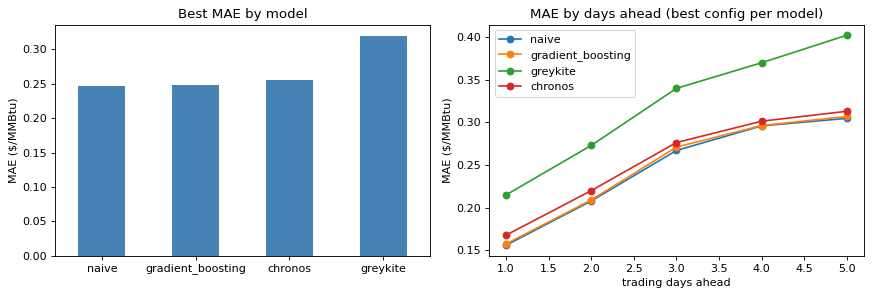

In [7]:
by_step = pd.DataFrame({name: report.metrics_by_step()["mae"] for name, report in best.items()})

figure, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8), dpi=80)
best_table["mae"].astype(float).plot.bar(ax=left, color="steelblue")
left.set_title("Best MAE by model")
left.set_ylabel("MAE ($/MMBtu)")
left.tick_params(axis="x", rotation=0)
by_step.plot(ax=right, marker="o")
right.set_title("MAE by days ahead (best config per model)")
right.set_xlabel("trading days ahead")
right.set_ylabel("MAE ($/MMBtu)")
figure.tight_layout()
plt.show()

## Best config

The publishing rule only picks a model over naive when it lowers error by at least the margin in `tuning.yaml`.

In [8]:
publisher = ModelPublisher(
    provider,
    tuning.registered_model_name,
    tuning.model_alias,
    tuning.selection_metric,
    tuning.min_improvement,
)
decision = publisher.choose(optimizer.reports)
print(decision.reason)
print("model to publish:", decision.report.model_name, decision.report.config.to_json())

naive had the lowest error
model to publish: naive {}


The grid search notebook publishes the official model. This notebook only reports what Bayesian search would pick.